In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, precision_score, f1_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.neural_network import MLPClassifier

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## Step 1: Load the training data

In [2]:
train = pd.read_csv("data/train.csv")
print(train.shape)
train.head()

(12680, 10)


,Name,Series,Platform,Year,Genre,Publisher,Num_Platforms,Already_Released,Hit,Series_Hit_Rate
0,Super Mario Bros.,super mario,NES,1985,Platform,Nintendo,1,0,1,0.129968
1,Mario Kart Wii,mario kart,Wii,2008,Racing,Nintendo,1,0,1,0.627129
2,Wii Sports Resort,wii sports,Wii,2009,Sports,Nintendo,1,0,1,0.129968
3,Pokemon Red/Pokemon Blue,pokemon red,GB,1996,Role-Playing,Nintendo,1,0,1,0.129968
4,Tetris,tetris,GB,1989,Puzzle,Nintendo,2,1,1,0.129968


## Step 2: Features (X), target (y), and groups 

In [3]:
features = ["Platform", "Year", "Genre", "Publisher", "Num_Platforms", "Already_Released", "Series_Hit_Rate"]

X = train[features]
y = train["Hit"]
groups = train["Name"]

print("X:", X.shape)
print("y:", y.shape)
print("groups:", groups.shape)

X: (12680, 7)
y: (12680,)
groups: (12680,)


## Step 3: Prep (words → numbers, scale numbers)

In [4]:


word_cols = ["Platform", "Genre", "Publisher"]
number_cols = ["Year", "Num_Platforms", "Series_Hit_Rate"]

prep = ColumnTransformer([
    ("words", OneHotEncoder(handle_unknown="ignore"), word_cols),
    ("numbers", StandardScaler(), number_cols),
], remainder="passthrough")

In [5]:
X_ready = prep.fit_transform(X)
print("Before:", X.shape)
print("After:", X_ready.shape)

Before: (12680, 7)
After: (12680, 179)


## Step 4: Set up 5-fold

In [6]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for i, (train_idx, quiz_idx) in enumerate(cv.split(X, y, groups), start=1):
    print(f"Fold {i}: {len(quiz_idx)} games in quiz chunk | hit rate {y.iloc[quiz_idx].mean() * 100:.1f}%")

Fold 1: 2539 games in quiz chunk | hit rate 13.0%
Fold 2: 2535 games in quiz chunk | hit rate 13.0%
Fold 3: 2535 games in quiz chunk | hit rate 13.0%
Fold 4: 2535 games in quiz chunk | hit rate 13.0%
Fold 5: 2536 games in quiz chunk | hit rate 13.0%


## Step 5: Lazy baseline (always says "not a hit") 

In [7]:
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": "recall",
    "f1": make_scorer(f1_score, zero_division=0),
}

baseline = Pipeline([("prep", prep), ("model", DummyClassifier(strategy="most_frequent"))])
scores = cross_validate(baseline, X, y, groups=groups, cv=cv, scoring=scoring)

for name in scoring:
    print(f"{name}: {scores['test_' + name].mean():.3f}")

accuracy: 0.870
precision: 0.000
recall: 0.000
f1: 0.000


## Step 6: Train the 5 models
To avoid **overfitting**, we only accept settings where the train F1 and quiz F1 are at most 0.10 apart. From those, we pick the best quiz F1.
### Model 1: Decision Tree

In [8]:
MAX_GAP = 0.10

def pick_best(cv_results):
    quiz = np.array(cv_results["mean_test_f1"])
    gap = np.array(cv_results["mean_train_f1"]) - quiz
    allowed = np.where(gap <= MAX_GAP)[0]
    if len(allowed) == 0:
        return int(np.argmin(gap))
    return int(allowed[np.argmax(quiz[allowed])])

In [9]:
def show_results(search):
    best = search.best_index_
    print("Best knobs:", search.best_params_)
    for name in scoring:
        print(f"{name}: {search.cv_results_['mean_test_' + name][best]:.3f}")
    print(f"Train F1: {search.cv_results_['mean_train_f1'][best]:.3f} | Quiz F1: {search.cv_results_['mean_test_f1'][best]:.3f}")

tree_pipe = Pipeline([("prep", prep), ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))])

tree_knobs = {
    "model__max_depth": [5, 10, 15, 20, None],
    "model__min_samples_leaf": [1, 5, 10, 20],
    "model__class_weight": [None, "balanced"],
}

tree_search = GridSearchCV(tree_pipe, tree_knobs, scoring=scoring, refit=pick_best, cv=cv, n_jobs=-1, return_train_score=True)
tree_search.fit(X, y, groups=groups)
show_results(tree_search)

Best knobs: {'model__class_weight': 'balanced', 'model__max_depth': 15, 'model__min_samples_leaf': 10}
accuracy: 0.760
precision: 0.309
recall: 0.679
f1: 0.424
Train F1: 0.519 | Quiz F1: 0.424


### Model 2: KNN 

In [10]:
knn_pipe = Pipeline([("prep", prep), ("model", KNeighborsClassifier())])

knn_knobs = {
    "model__n_neighbors": [3, 5, 7, 11, 15, 31],
    "model__weights": ["uniform", "distance"],
}

knn_search = GridSearchCV(knn_pipe, knn_knobs, scoring=scoring, refit=pick_best, cv=cv, n_jobs=-1, return_train_score=True)
knn_search.fit(X, y, groups=groups)
show_results(knn_search)

Best knobs: {'model__n_neighbors': 11, 'model__weights': 'uniform'}
accuracy: 0.882
precision: 0.601
recall: 0.281
f1: 0.382
Train F1: 0.471 | Quiz F1: 0.382


### Model 3: Logistic Regression 

In [11]:
from sklearn.linear_model import LogisticRegression

log_pipe = Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=2000))])

log_knobs = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__class_weight": [None, "balanced"],
}

log_search = GridSearchCV(log_pipe, log_knobs, scoring=scoring, refit=pick_best, cv=cv, n_jobs=-1, return_train_score=True)
log_search.fit(X, y, groups=groups)
show_results(log_search)

Best knobs: {'model__C': 0.1, 'model__class_weight': 'balanced'}
accuracy: 0.770
precision: 0.330
recall: 0.747
f1: 0.458
Train F1: 0.472 | Quiz F1: 0.458


### Model 4: Random Forest 

In [12]:
from sklearn.ensemble import RandomForestClassifier

rf_pipe = Pipeline([("prep", prep), ("model", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE))])

rf_knobs = {
    "model__max_depth": [10, 20, None],
    "model__min_samples_leaf": [1, 2, 3, 5],
    "model__class_weight": [None, "balanced"],
}

rf_search = GridSearchCV(rf_pipe, rf_knobs, scoring=scoring, refit=pick_best, cv=cv, n_jobs=-1, return_train_score=True)
rf_search.fit(X, y, groups=groups)
show_results(rf_search)

Best knobs: {'model__class_weight': 'balanced', 'model__max_depth': 20, 'model__min_samples_leaf': 2}
accuracy: 0.812
precision: 0.379
recall: 0.705
f1: 0.493
Train F1: 0.579 | Quiz F1: 0.493


### Model 5: Neural Network 

In [13]:
nn_pipe = Pipeline([("prep", prep), ("model", MLPClassifier(max_iter=100, random_state=RANDOM_STATE))])

nn_knobs = {
    "model__hidden_layer_sizes": [(16,), (32,), (64,)],
    "model__alpha": [0.01, 0.1, 1.0],
    "model__early_stopping": [False],
}

nn_search = GridSearchCV(nn_pipe, nn_knobs, scoring=scoring, refit=pick_best, cv=cv, n_jobs=-1, return_train_score=True)
nn_search.fit(X, y, groups=groups)
show_results(nn_search)

/Users/amrindersingh/Desktop/Exam-mid/env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/amrindersingh/Desktop/Exam-mid/env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/amrindersingh/Desktop/Exam-mid/env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/amrindersingh/Desktop/Exam-mid/env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization

/Users/amrindersingh/Desktop/Exam-mid/env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/amrindersingh/Desktop/Exam-mid/env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/amrindersingh/Desktop/Exam-mid/env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/amrindersingh/Desktop/Exam-mid/env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization

/Users/amrindersingh/Desktop/Exam-mid/env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


/Users/amrindersingh/Desktop/Exam-mid/env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/amrindersingh/Desktop/Exam-mid/env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


/Users/amrindersingh/Desktop/Exam-mid/env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/amrindersingh/Desktop/Exam-mid/env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


/Users/amrindersingh/Desktop/Exam-mid/env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/amrindersingh/Desktop/Exam-mid/env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


... (8 outputs left out)

/Users/amrindersingh/Desktop/Exam-mid/env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


/Users/amrindersingh/Desktop/Exam-mid/env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


Best knobs: {'model__alpha': 0.1, 'model__early_stopping': False, 'model__hidden_layer_sizes': (32,)}
accuracy: 0.888
precision: 0.637
recall: 0.327
f1: 0.431
Train F1: 0.515 | Quiz F1: 0.431


/Users/amrindersingh/Desktop/Exam-mid/env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


## Step 7: Compare the models

In [14]:
searches = {
    "Decision Tree": tree_search,
    "KNN": knn_search,
    "Logistic Regression": log_search,
    "Random Forest": rf_search,
    "Neural Network": nn_search,
}

missing = [name for name, s in searches.items() if not hasattr(s, "best_index_")]

if missing:
    print("NOT trained ❌ → re-run these model cells first:", missing)
else:
    rows = [{"Model": "Baseline", "accuracy": scores["test_accuracy"].mean(), "precision": 0, "recall": 0, "f1": 0, "train_f1": 0}]
    for name, search in searches.items():
        best = search.best_index_
        row = {"Model": name}
        for metric in scoring:
            row[metric] = search.cv_results_["mean_test_" + metric][best]
        row["train_f1"] = search.cv_results_["mean_train_f1"][best]
        rows.append(row)

    results = pd.DataFrame(rows).sort_values("f1", ascending=False).round(3)
    display(results)

,Model,accuracy,precision,recall,f1,train_f1
4,Random Forest,0.812,0.379,0.705,0.493,0.579
3,Logistic Regression,0.770,0.330,0.747,0.458,0.472
5,Neural Network,0.888,0.637,0.327,0.431,0.515
1,Decision Tree,0.760,0.309,0.679,0.424,0.519
2,KNN,0.882,0.601,0.281,0.382,0.471
0,Baseline,0.870,0.000,0.000,0.000,0.000


In [15]:
for name, s in searches.items():
    print(name, "→", "OK ✅" if "mean_train_f1" in s.cv_results_ else "missing train scores ❌")

Decision Tree → OK ✅
KNN → OK ✅
Logistic Regression → OK ✅
Random Forest → OK ✅
Neural Network → OK ✅


### Confusion matrices (5-fold) 

In [16]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix

all_preds = {}
for name, search in searches.items():
    all_preds[name] = cross_val_predict(search.best_estimator_, X, y, groups=groups, cv=cv, n_jobs=-1)

/Users/amrindersingh/Desktop/Exam-mid/env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/amrindersingh/Desktop/Exam-mid/env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/amrindersingh/Desktop/Exam-mid/env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/amrindersingh/Desktop/Exam-mid/env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization

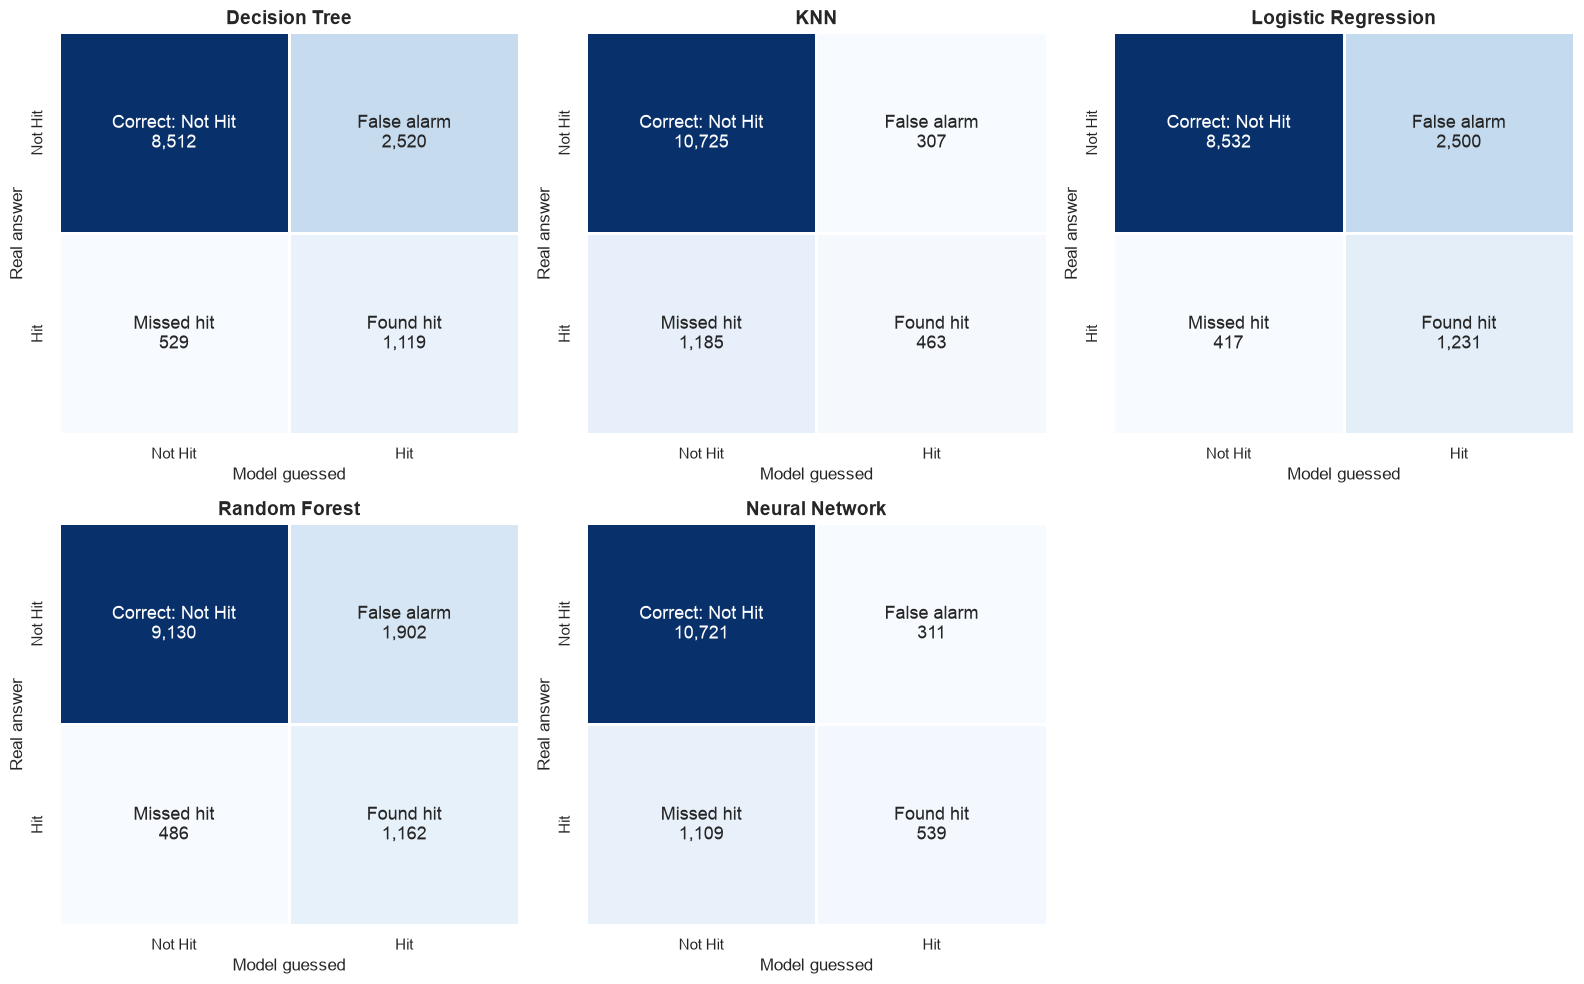

In [17]:
box_names = [["Correct: Not Hit", "False alarm"],
             ["Missed hit", "Found hit"]]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for ax, (name, preds) in zip(axes, all_preds.items()):
    cm = confusion_matrix(y, preds)
    labels = [[f"{box_names[r][c]}\n{cm[r, c]:,}" for c in range(2)] for r in range(2)]
    sns.heatmap(cm, annot=labels, fmt="", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Not Hit", "Hit"], yticklabels=["Not Hit", "Hit"],
                annot_kws={"size": 13}, linewidths=2, linecolor="white")
    ax.grid(False)
    ax.set_title(name, fontsize=14, fontweight="bold")
    ax.set_xlabel("Model guessed")
    ax.set_ylabel("Real answer")

axes[5].axis("off")


plt.tight_layout()
plt.savefig("charts/confusion_matrices_5fold.png", dpi=150, bbox_inches="tight")
plt.show()

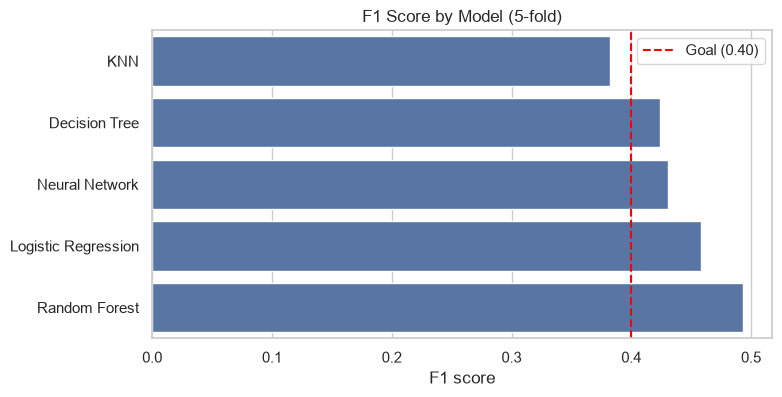

In [18]:
plot_df = results[results["Model"] != "Baseline"].sort_values("f1")

plt.figure(figsize=(8, 4))
sns.barplot(data=plot_df, x="f1", y="Model")
plt.axvline(0.40, color="red", linestyle="--", label="Goal (0.40)")
plt.title("F1 Score by Model (5-fold)")
plt.xlabel("F1 score")
plt.ylabel("")
plt.legend()
plt.savefig("charts/f1_by_model.png", dpi=150, bbox_inches="tight")
plt.show()

### Check: overfitting and underfitting

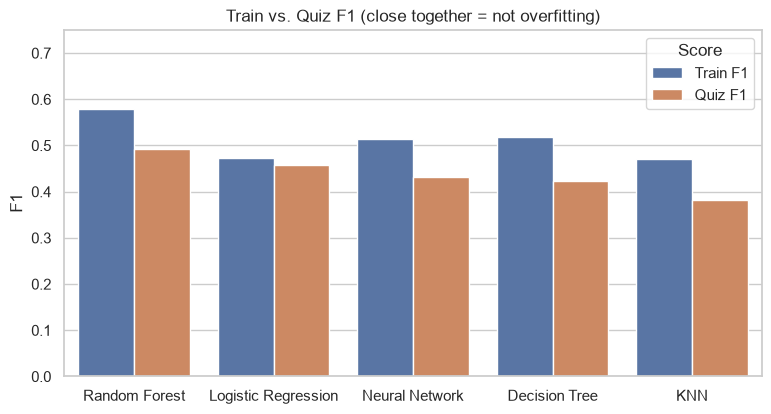

,Model,train_f1,f1,gap
4,Random Forest,0.579,0.493,0.086
3,Logistic Regression,0.472,0.458,0.014
5,Neural Network,0.515,0.431,0.084
1,Decision Tree,0.519,0.424,0.095
2,KNN,0.471,0.382,0.089
0,Baseline,0.000,0.000,0.000


In [19]:
gap_df = results[results["Model"] != "Baseline"].melt(id_vars="Model", value_vars=["train_f1", "f1"], var_name="Score", value_name="F1")
gap_df["Score"] = gap_df["Score"].map({"train_f1": "Train F1", "f1": "Quiz F1"})

plt.figure(figsize=(9, 4.5))
sns.barplot(data=gap_df, x="Model", y="F1", hue="Score")
plt.title("Train vs. Quiz F1 (close together = not overfitting)")
plt.xlabel("")
plt.ylim(0, 0.75)
plt.savefig("charts/train_vs_quiz_f1.png", dpi=150, bbox_inches="tight")
plt.show()

results.assign(gap=(results["train_f1"] - results["f1"]).round(3))[["Model", "train_f1", "f1", "gap"]]

In [20]:


winner = rf_search.best_estimator_

test = pd.read_csv("data/test.csv")
X_test = test[features]
y_test = test["Hit"]

test_preds = winner.predict(X_test)

print("Final test scores (Random Forest):")
print(f"accuracy:  {accuracy_score(y_test, test_preds):.3f}")
print(f"precision: {precision_score(y_test, test_preds):.3f}")
print(f"recall:    {recall_score(y_test, test_preds):.3f}")
print(f"f1:        {f1_score(y_test, test_preds):.3f}")

Final test scores (Random Forest):
accuracy:  0.820
precision: 0.383
recall:    0.736
f1:        0.503


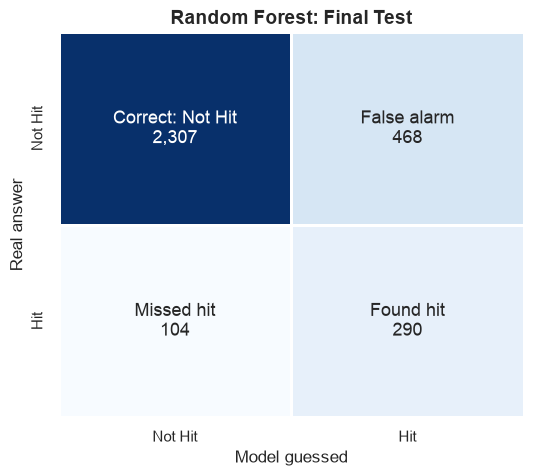

In [21]:
cm = confusion_matrix(y_test, test_preds)
labels = [[f"{box_names[r][c]}\n{cm[r, c]:,}" for c in range(2)] for r in range(2)]

plt.figure(figsize=(6, 5))
ax = sns.heatmap(cm, annot=labels, fmt="", cmap="Blues", cbar=False,
                 xticklabels=["Not Hit", "Hit"], yticklabels=["Not Hit", "Hit"],
                 annot_kws={"size": 13}, linewidths=2, linecolor="white")
ax.grid(False)
plt.title("Random Forest: Final Test", fontsize=14, fontweight="bold")
plt.xlabel("Model guessed")
plt.ylabel("Real answer")
plt.savefig("charts/confusion_matrix_test.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 10: Save results 

In [22]:
import json

best_settings = {name: search.best_params_ for name, search in searches.items()}

with open("results/best_settings.json", "w") as f:
    json.dump(best_settings, f, indent=2)

results.to_csv("results/model_scores.csv", index=False)

print("Saved! ✅")
print(json.dumps(best_settings, indent=2))

Saved! ✅
{
  "Decision Tree": {
    "model__class_weight": "balanced",
    "model__max_depth": 15,
    "model__min_samples_leaf": 10
  },
  "KNN": {
    "model__n_neighbors": 11,
    "model__weights": "uniform"
  },
  "Logistic Regression": {
    "model__C": 0.1,
    "model__class_weight": "balanced"
  },
  "Random Forest": {
    "model__class_weight": "balanced",
    "model__max_depth": 20,
    "model__min_samples_leaf": 2
  },
  "Neural Network": {
    "model__alpha": 0.1,
    "model__early_stopping": false,
    "model__hidden_layer_sizes": [
      32
    ]
  }
}
